# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

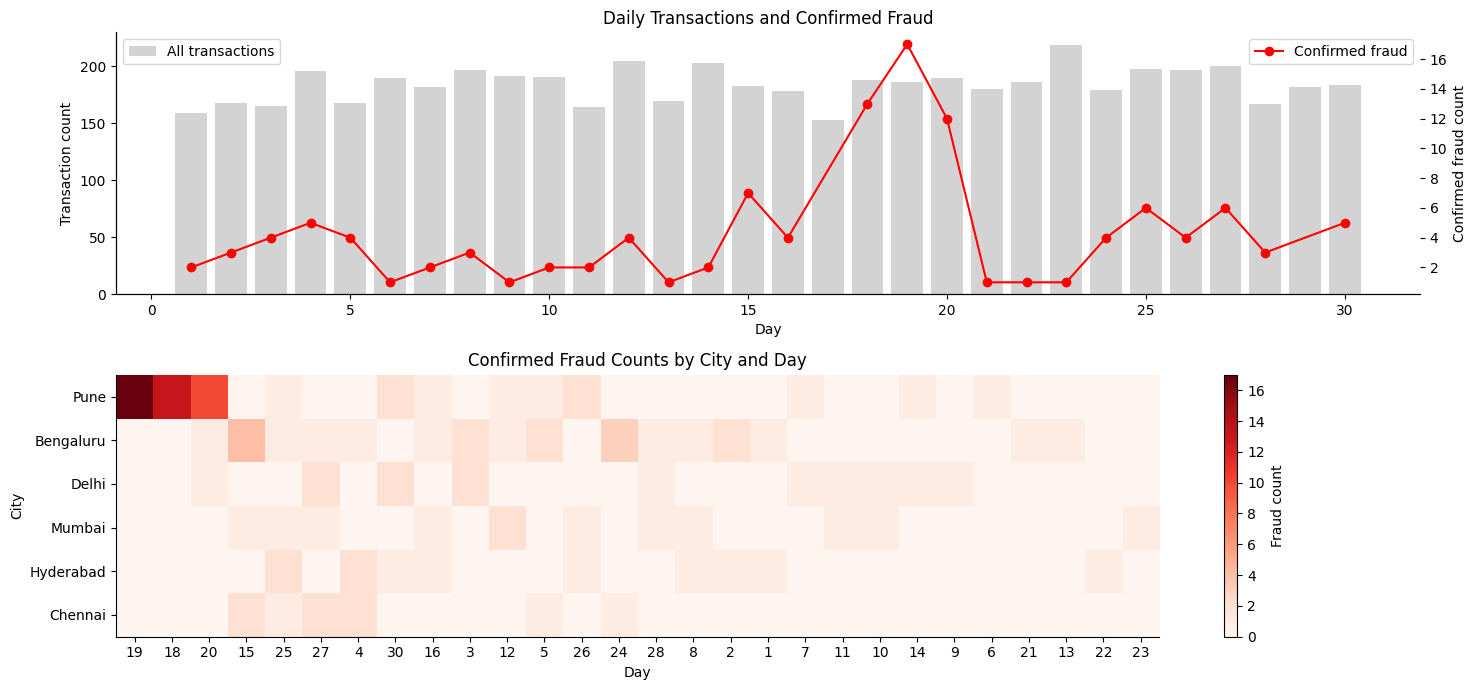

Top city-day combinations by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  5       2
Hyderabad  25      2
           4       2
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily transaction counts and confirmed fraud counts
daily_total = tx.groupby("day").size()
daily_fraud = tx[tx["is_fraud"] == 1].groupby("day").size()

axes[0].bar(daily_total.index, daily_total.values,
            color="lightgrey", label="All transactions")
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values,
         color="red", marker="o", label="Confirmed fraud")

axes[0].set_title("Daily Transactions and Confirmed Fraud")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Transaction count")
ax2.set_ylabel("Confirmed fraud count")
axes[0].legend(loc="upper left")
ax2.legend(loc="upper right")


# TODO 2: City × day matrix of confirmed-fraud counts
fraud = tx[tx["is_fraud"] == 1]

heat = fraud.pivot_table(
    index="city",
    columns="day",
    values="txn_id",
    aggfunc="count",
    fill_value=0
)

# Reorder cities and days by their total fraud counts
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_title("Confirmed Fraud Counts by City and Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("City")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
fig.colorbar(im, ax=axes[1], label="Fraud count")


plt.tight_layout()
plt.show()


# TODO 3: Print the city-day combinations with the most fraud
print("Top city-day combinations by confirmed fraud:")
print(heat.stack().sort_values(ascending=False).head(10))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview revealed patterns in fraud activity across different days and cities, including clusters of unusually high fraud counts that a score-sorted alert list would not show. The lecture concept is overview first and reordering a matrix (Slide 39), which makes hidden patterns easier to identify by arranging rows and columns by their totals.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

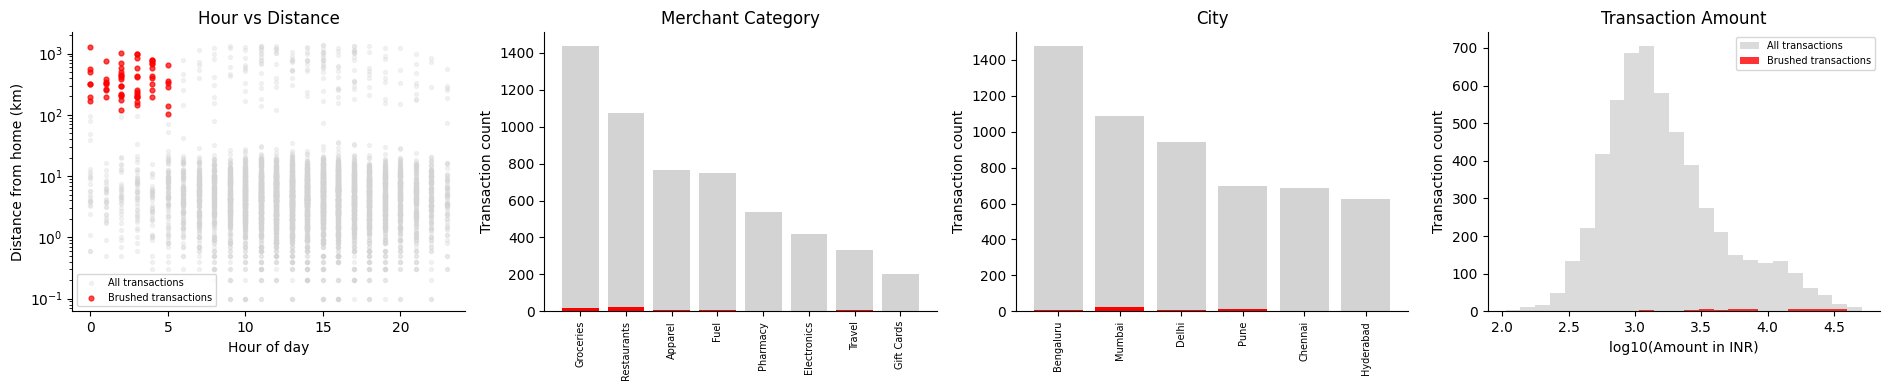

Transactions inside brush: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all confirmed fraud captured: 44.17%


In [3]:
# TODO 1: Brush night-time transactions more than 100 km from home
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)
brushed = tx[brush]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs distance from home (logarithmic y-axis)
axes[0].scatter(
    tx["hour"], tx["distance_from_home_km"],
    color="lightgrey", alpha=0.25, s=8, label="All transactions"
)
axes[0].scatter(
    brushed["hour"], brushed["distance_from_home_km"],
    color="red", alpha=0.7, s=12, label="Brushed transactions"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")
axes[0].legend(fontsize=7)

# Find the merchant category column
category_col = (
    "merchant_category"
    if "merchant_category" in tx.columns
    else "category"
)

# TODO 2(b): Merchant category counts
all_category = tx[category_col].value_counts()
brush_category = brushed[category_col].value_counts()

axes[1].bar(
    all_category.index.astype(str), all_category.values,
    color="lightgrey", label="All transactions"
)
axes[1].bar(
    brush_category.index.astype(str), brush_category.reindex(
        all_category.index, fill_value=0
    ).values,
    color="red", label="Brushed transactions"
)
axes[1].set_title("Merchant Category")
axes[1].set_ylabel("Transaction count")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)

# TODO 2(c): City counts
all_city = tx["city"].value_counts()
brush_city = brushed["city"].value_counts()

axes[2].bar(
    all_city.index.astype(str), all_city.values,
    color="lightgrey", label="All transactions"
)
axes[2].bar(
    brush_city.index.astype(str), brush_city.reindex(
        all_city.index, fill_value=0
    ).values,
    color="red", label="Brushed transactions"
)
axes[2].set_title("City")
axes[2].set_ylabel("Transaction count")
axes[2].tick_params(axis="x", rotation=90, labelsize=7)

# TODO 2(d): Amount histogram using log10
all_amount = np.log10(tx["amount_inr"].clip(lower=1))
brush_amount = np.log10(brushed["amount_inr"].clip(lower=1))

bins = np.linspace(all_amount.min(), all_amount.max(), 25)

axes[3].hist(
    all_amount, bins=bins,
    color="lightgrey", alpha=0.8, label="All transactions"
)
axes[3].hist(
    brush_amount, bins=bins,
    color="red", alpha=0.8, label="Brushed transactions"
)
axes[3].set_title("Transaction Amount")
axes[3].set_xlabel("log10(Amount in INR)")
axes[3].set_ylabel("Transaction count")
axes[3].legend(fontsize=7)

plt.tight_layout()
plt.show()

# TODO 3: Print brush statistics
inside_n = int(brush.sum())
inside_fraud = int(tx.loc[brush, "is_fraud"].sum())
total_fraud = int(tx["is_fraud"].sum())

inside_fraud_rate = inside_fraud / inside_n if inside_n else 0
overall_fraud_rate = tx["is_fraud"].mean()
fraud_captured = inside_fraud / total_fraud * 100 if total_fraud else 0

print(f"Transactions inside brush: {inside_n:,}")
print(f"Fraud rate inside brush: {inside_fraud_rate:.2%}")
print(f"Overall fraud rate: {overall_fraud_rate:.2%}")
print(f"Share of all confirmed fraud captured: {fraud_captured:.2f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush identified 61 transactions, of which 86.89% were confirmed fraud, compared with an overall fraud rate of just 2.17%. However, it captured only 44.17% of all confirmed fraud, meaning 55.83% of fraud was missed by this rule.

This tells investigators that the night-time, far-from-home rule is highly effective at identifying suspicious transactions, but relying on it alone would leave more than half of all fraud undetected. The City linked view hints at where the remaining fraud may be: Bengaluru, Mumbai and Delhi have high overall transaction counts, while the brush captures only a small portion of activity in those cities.

Conclusion: Use this rule as one signal in a broader fraud-detection system, not as the sole condition for raising alerts.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Time the filter 5 times and keep the fastest result
times = []

for _ in range(5):
    start = time.perf_counter()

    mask = (
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    )

    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: Calculate per-item cost and maximum rows for a 0.1-second response
per_item_us = (best_s / len(big)) * 1_000_000

time_per_row = best_s / len(big)
max_rows = int(0.1 / time_per_row) if time_per_row > 0 else 0

# TODO 3: Estimate performance for 50 million rows
t_50m = per_item_us * 1e-6 * 50_000_000

skip_pct = (
    max(0, (1 - (0.1 / t_50m)) * 100)
    if t_50m > 0 else 0
)

print(
    f"{len(big):,} rows in {best_s*1000:.1f} ms "
    f"-> {per_item_us:.4f} us/row "
    f"-> max {max_rows:,.0f} rows in 0.1 s"
)

print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)

1,004,640 rows in 13.8 ms -> 0.0138 us/row -> max 7,264,937 rows in 0.1 s
50M rows -> 0.69 s; must skip 85.5% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

One reduce technique is pre-aggregation: group transactions into summaries (such as fraud counts by city, hour, or merchant category) and let the slider filter those summaries instead of scanning all 50 million individual rows.

This keeps interaction fast, but the analyst loses transaction-level detail. They cannot inspect every individual transaction or identify specific outliers from the aggregated view.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

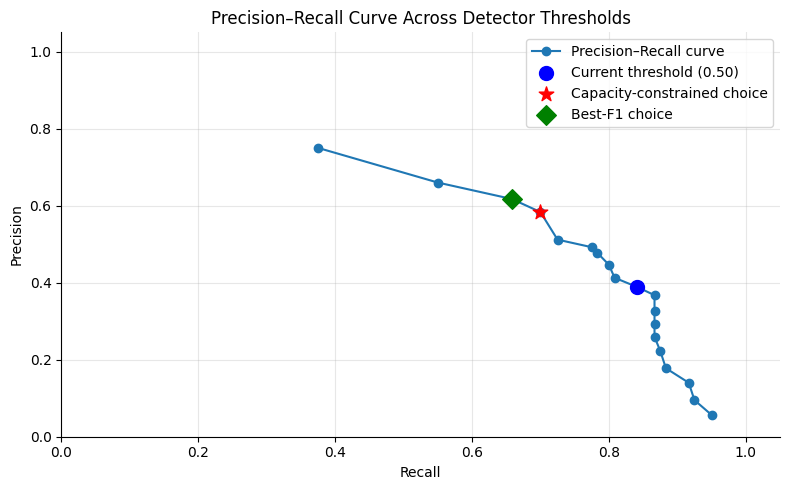

RECOMMENDATION: Use threshold 0.80 to stay within the 150-alert monthly capacity. It produces 144 alerts, with precision 58.33% and recall 70.00%.
Best-F1 threshold: 0.85 (F1 = 0.637, alerts = 128).


In [5]:
rows = []

# TODO 1: Calculate metrics for thresholds from 0.05 to 0.95
y_true = tx["is_fraud"].astype(int)
scores = tx["detector_score"]

for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = scores >= threshold

    tp = int(((predicted) & (y_true == 1)).sum())
    fp = int(((predicted) & (y_true == 0)).sum())
    fn = int(((~predicted) & (y_true == 1)).sum())

    alerts = tp + fp

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    rows.append({
        "threshold": round(float(threshold), 2),
        "alerts": alerts,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Find capacity-constrained and best-F1 thresholds
eligible = pr[pr["alerts"] <= 150]

if eligible.empty:
    raise ValueError("No threshold produces 150 or fewer alerts.")

capacity_choice = eligible.sort_values(
    ["recall", "threshold"],
    ascending=[False, False]
).iloc[0]

best_f1 = pr.loc[pr["f1"].idxmax()]

# Current threshold
current = pr.loc[pr["threshold"] == 0.50].iloc[0]

# TODO 3: Plot precision-recall curve and mark the three choices
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"], pr["precision"],
    marker="o", label="Precision–Recall curve"
)

ax.scatter(
    current["recall"], current["precision"],
    color="blue", s=100, label="Current threshold (0.50)", zorder=3
)

ax.scatter(
    capacity_choice["recall"], capacity_choice["precision"],
    color="red", s=120, marker="*", label="Capacity-constrained choice", zorder=4
)

ax.scatter(
    best_f1["recall"], best_f1["precision"],
    color="green", s=100, marker="D", label="Best-F1 choice", zorder=3
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve Across Detector Thresholds")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: Print recommendation
print(
    f"RECOMMENDATION: Use threshold {capacity_choice['threshold']:.2f} "
    f"to stay within the 150-alert monthly capacity. "
    f"It produces {int(capacity_choice['alerts'])} alerts, "
    f"with precision {capacity_choice['precision']:.2%} "
    f"and recall {capacity_choice['recall']:.2%}."
)

print(
    f"Best-F1 threshold: {best_f1['threshold']:.2f} "
    f"(F1 = {best_f1['f1']:.3f}, "
    f"alerts = {int(best_f1['alerts'])})."
)

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make the final decision, not the model. The model provides metrics such as precision, recall and F1, but it cannot decide how to balance fraud detection against the team's limited investigation capacity.

Visual analytics keeps a human in the loop because people must interpret the results, consider business priorities, assess the consequences of false positives and false negatives, and take responsibility for the decision. The model supports human judgement; it should not replace it.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1: Interactive scatter plot of flagged transactions
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=[
        "txn_id",
        "customer_id",
        "city",
        "merchant_category",
        "distance_from_home_km",
        "detector_score"
    ],
    title="Flagged Transactions (Detector Score ≥ 0.3)"
)

fig_scatter.update_layout(
    dragmode="select",
    xaxis_title="Transaction Timestamp",
    yaxis_title="Transaction Amount (INR, log scale)"
)

fig_scatter.show()


# TODO 2: Interactive sunburst — City → Merchant Category
sun = tx.groupby(
    ["city", "merchant_category"],
    as_index=False
).agg(
    transactions=("txn_id", "count"),
    fraud_rate=("is_fraud", "mean")
)

fig_sun = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transactions",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Transaction Breakdown by City and Merchant Category",
    hover_data=["fraud_rate"]
)

fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips require investigators to hover over each transaction individually, which becomes slow and frustrating when reviewing 400 flagged cases. They also make it difficult to compare cases and spot overall patterns because investigators must remember details from one transaction to the next.

The overview heatmap from Task 1 (city * day fraud counts) fixes this by showing where fraud is concentrated across the month at a glance. Investigators can use the overview to identify patterns first, then use tooltips for individual transaction details.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

In [8]:
from scipy.stats import chi2_contingency

# TODO 1: Identify the top city and peak day from Task 1
top_cell = heat.stack().idxmax()
ring_city, peak_day = top_cell

start_day = max(int(tx["day"].min()), int(peak_day) - 1)
end_day = min(int(tx["day"].max()), int(peak_day) + 1)

in_window = (
    (tx["city"] == ring_city) &
    (tx["day"].between(start_day, end_day))
)

print(
    f"Hypothesis: elevated fraud activity in {ring_city}, "
    f"from day {start_day} to day {end_day}."
)

# TODO 2: Compare fraud rates and perform chi-square test
inside = tx[in_window]
outside = tx[~in_window]

inside_rate = inside["is_fraud"].mean()
outside_rate = outside["is_fraud"].mean()

contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"\nFraud rate inside window:  {inside_rate:.2%}")
print(f"Fraud rate outside window: {outside_rate:.2%}")
print(f"Chi-square statistic:      {chi2:.3f}")
print(f"P-value:                   {p_value:.6f}")

# TODO 3: Search for counter-examples
same_city_other_days = (
    (tx["city"] == ring_city) &
    (~tx["day"].between(start_day, end_day))
)

other_cities_same_days = (
    (tx["city"] != ring_city) &
    (tx["day"].between(start_day, end_day))
)

rest = (
    (tx["city"] != ring_city) &
    (~tx["day"].between(start_day, end_day))
)

groups = {
    "Suspected window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest
}

# TODO 4: Visual comparison of the four groups
group_rates = {}
group_counts = {}

for name, mask in groups.items():
    subset = tx[mask]
    group_rates[name] = subset["is_fraud"].mean()
    group_counts[name] = len(subset)

names = list(groups.keys())
rates = [group_rates[name] * 100 for name in names]

bars = ax.bar(names, rates, color=["red", "orange", "steelblue", "lightgrey"])

ax.set_title("Fraud Rates: Suspected Window vs Counter-examples")
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_xlabel("Transaction group")
ax.tick_params(axis="x", rotation=15)

for bar, name in zip(bars, names):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{group_rates[name]:.2%}\n(n={group_counts[name]:,})",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

# TODO 5: Print verdict
print("\nVERDICT:")

if p_value < 0.05 and inside_rate > outside_rate:
    print(
        "The suspected city-day window has a statistically significant "
        "higher fraud rate than the rest of the transactions. "
        "This supports the hypothesis, but does not prove an organised fraud ring."
    )
else:
    print(
        "The evidence does not establish a statistically significant "
        "higher fraud rate in the suspected window. The fraud-ring hypothesis "
        "is not supported by this test."
    )

print(
    f"Same city, other days: {group_rates['Same city, other days']:.2%}"
)
print(
    f"Other cities, same days: {group_rates['Other cities, same days']:.2%}"
)

Hypothesis: elevated fraud activity in Pune, from day 18 to day 20.

Fraud rate inside window:  37.38%
Fraud rate outside window: 1.48%
Chi-square statistic:      619.294
P-value:                   0.000000


<Figure size 640x480 with 0 Axes>


VERDICT:
The suspected city-day window has a statistically significant higher fraud rate than the rest of the transactions. This supports the hypothesis, but does not prove an organised fraud ring.
Same city, other days: 1.85%
Other cities, same days: 0.44%


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The “other cities, same days” counter-example would be especially important. If those cities also had similarly high fraud rates during the same period, the hypothesis of a specific fraud ring in one city would be weakened. It would suggest a broader time-based event, such as a system-wide attack or coordinated fraud activity across multiple cities, rather than a ring concentrated in one city.

The “same city, other days” comparison also matters: if fraud remained high on other days, it could indicate an ongoing city-specific issue rather than a short-lived fraud ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

**To: Head of Fraud Ops — Monthly Review**

Last month, PayKart recorded an overall fraud rate of 2.17%, while the night-time, far-from-home rule identified 61 transactions with an 86.89% fraud rate but captured only 44.17% of all confirmed fraud. **I strongly recommend setting the detector threshold at 0.80**, producing 144 alerts per month with 58.33% precision and 70.00% recall, keeping the team within its 150-alert capacity while detecting a substantial majority of confirmed fraud. The best-F1 threshold of 0.85 is not my recommendation because the priority is to maximise fraud detection within the team's actual review capacity, not simply optimise a statistical score. Build the **linked-brushing dashboard first** so investigators can identify suspicious patterns across time, cities, merchant categories and transaction amounts before drilling into individual cases. Finally, establish a continuous human feedback loop that feeds investigators' confirmed fraud labels and false-positive findings back into detector training and evaluation to improve next month's results.